Do you want to enter custom data? (yes/no):  NO



--- Running Built-in Example (City Road Network) ---

--- Adjacency List ---
A -> B(Cost: 5), C(Cost: 15)
B -> A(Cost: 5), C(Cost: 10)
C -> A(Cost: 15), B(Cost: 10)
D -> None

--- Adjacency Matrix ---
           A     B     C     D
A          0     5    15   INF
B          5     0    10   INF
C         15    10     0   INF
D        INF   INF   INF     0

--- Connectivity Analysis from Source: A ---
BFS Traversal Order: A -> B -> C
DFS Traversal Order: A -> B -> C
Reachable intersections from A: B, C

--- Connectivity Analysis from Source: D ---
BFS Traversal Order: D
DFS Traversal Order: D
Reachable intersections from D: None (Isolated intersection)


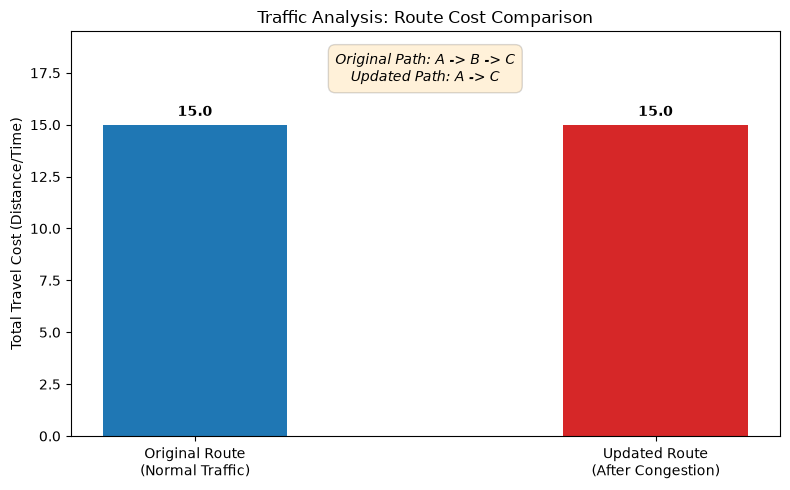

In [8]:
import sys
from collections import deque
import matplotlib.pyplot as plt

class RoadNetwork:
    def __init__(self):
        self.adj_list = {}

    def add_intersection(self, vertex):
        if vertex not in self.adj_list:
            self.adj_list[vertex] = {}

    def add_road(self, u, v, weight):
        self.add_intersection(u)
        self.add_intersection(v)
        self.adj_list[u][v] = weight
        self.adj_list[v][u] = weight

    def display_adj_list(self):
        print("\n--- Adjacency List ---")
        if not self.adj_list:
            print("Empty Graph")
            return
        for vertex in sorted(self.adj_list.keys()):
            connections = ", ".join([f"{neighbor}(Cost: {weight})" for neighbor, weight in sorted(self.adj_list[vertex].items())])
            print(f"{vertex} -> {connections if connections else 'None'}")

    def display_adj_matrix(self):
        print("\n--- Adjacency Matrix ---")
        vertices = sorted(list(self.adj_list.keys()))
        if not vertices:
            print("Empty Graph")
            return
        
        max_cell_w = max([4] + [len(str(v)) for v in vertices] + 
                         [len(f"{self.adj_list[u][v]:.1f}") for u in vertices for v in vertices if v in self.adj_list[u]])
        col_width = max_cell_w + 2

        print(f"{'':<{col_width}}" + "".join([f"{v:>{col_width}}" for v in vertices]))
        for u in vertices:
            row = []
            for v in vertices:
                if u == v and v not in self.adj_list[u]:
                    row.append(f"{'0':>{col_width}}")
                elif v in self.adj_list[u]:
                    val = self.adj_list[u][v]
                    row.append(f"{f'{val:.1f}' if isinstance(val, float) else str(val):>{col_width}}")
                else:
                    row.append(f"{'INF':>{col_width}}")
            print(f"{u:<{col_width}}" + "".join(row))

    def analyze_connectivity(self, start_node):
        if start_node not in self.adj_list:
            print(f"\nIntersection '{start_node}' does not exist in the network.")
            return

        print(f"\n--- Connectivity Analysis from Source: {start_node} ---")
        
        bfs_order = []
        bfs_visited = set([start_node])
        queue = deque([start_node])
        
        while queue:
            curr = queue.popleft()
            bfs_order.append(curr)
            for neighbor in sorted(self.adj_list[curr].keys()):
                if neighbor not in bfs_visited:
                    bfs_visited.add(neighbor)
                    queue.append(neighbor)
                    
        print(f"BFS Traversal Order: {' -> '.join(bfs_order)}")

        dfs_order = []
        dfs_visited = set()
        
        def dfs_recursive(node):
            dfs_visited.add(node)
            dfs_order.append(node)
            for neighbor in sorted(self.adj_list[node].keys()):
                if neighbor not in dfs_visited:
                    dfs_recursive(neighbor)
                    
        dfs_recursive(start_node)
        print(f"DFS Traversal Order: {' -> '.join(dfs_order)}")
        
        reachable = sorted(list(bfs_visited - {start_node}))
        if reachable:
            print(f"Reachable intersections from {start_node}: {', '.join(reachable)}")
        else:
            print(f"Reachable intersections from {start_node}: None (Isolated intersection)")

    def visualize_traffic_analysis(self, orig_route, updated_route, orig_costs, updated_costs):
        fig, ax = plt.subplots(figsize=(8, 5))
        
        labels = ['Original Route\n(Normal Traffic)', 'Updated Route\n(After Congestion)']
        total_orig_cost = sum(orig_costs)
        total_updated_cost = sum(updated_costs)
        costs = [total_orig_cost, total_updated_cost]
        
        bars = ax.bar(labels, costs, color=['#1f77b4', '#d62728'], width=0.4)
        
        ax.set_ylabel('Total Travel Cost (Distance/Time)')
        ax.set_title('Traffic Analysis: Route Cost Comparison')
        ax.set_ylim(0, max(costs) * 1.3)
        
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f'{height:.1f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),  
                        textcoords="offset points",
                        ha='center', va='bottom', weight='bold')

        route_info = f"Original Path: {' -> '.join(orig_route)}\nUpdated Path: {' -> '.join(updated_route)}"
        
        ax.text(0.5, 0.95, route_info, transform=ax.transAxes, fontsize=10, 
                style='italic', ha='center', va='top',
                bbox={'facecolor': 'orange', 'alpha': 0.15, 'pad': 6, 'boxstyle': 'round,pad=0.5'})
        
        plt.tight_layout()
        plt.show()

def run_example():
    print("\n--- Running Built-in Example (City Road Network) ---")
    network = RoadNetwork()
    network.add_road("A", "B", 5)
    network.add_road("B", "C", 10)
    network.add_road("A", "C", 15)
    network.add_intersection("D")
    network.display_adj_list()
    network.display_adj_matrix()
    
    network.analyze_connectivity("A")
    network.analyze_connectivity("D")
    
    orig_route = ["A", "B", "C"]
    orig_costs = [5, 10]
    
    updated_route = ["A", "C"]
    updated_costs = [15]
    
    network.visualize_traffic_analysis(orig_route, updated_route, orig_costs, updated_costs)

def run_custom():
    network = RoadNetwork()
    print("\n--- Custom Road Network Builder ---")
    try:
        v_count = int(input("Enter number of intersections to add: "))
        for _ in range(v_count):
            v = input("Enter intersection name: ").strip()
            network.add_intersection(v)
            
        e_count = int(input("Enter number of roads to add: "))
        for _ in range(e_count):
            u = input("Enter starting intersection: ").strip()
            v = input("Enter ending intersection: ").strip()
            weight = float(input("Enter travel cost (distance/time): "))
            network.add_road(u, v, weight)
            
        network.display_adj_list()
        network.display_adj_matrix()
        
        if network.adj_list:
            start_node = input("\nEnter starting node for connectivity analysis: ").strip()
            network.analyze_connectivity(start_node)
            
            print("\n--- Traffic Analysis Setup ---")
            orig_nodes = input("Enter Original Route nodes separated by space (e.g., A B C): ").strip().split()
            orig_c = [float(x) for x in input("Enter segment costs for Original Route separated by space (e.g., 5 10): ").strip().split()]
            
            up_nodes = input("Enter Updated Route nodes separated by space (e.g., A C): ").strip().split()
            up_c = [float(x) for x in input("Enter segment costs for Updated Route separated by space (e.g., 15): ").strip().split()]
            
            network.visualize_traffic_analysis(orig_nodes, up_nodes, orig_c, up_c)
            
    except ValueError:
        print("Invalid input sequence. Exiting.")

def main():
    choice = input("Do you want to enter custom data? (yes/no): ").strip().lower()
    if choice in ['yes', 'y']:
        run_custom()
    else:
        run_example()

if __name__ == "__main__":
    main()